# 🏟️ Evinde Kazanmak: Avrupa'nın 5 Büyük Liginde Ev Sahibi Avantajı

*Google Data Analytics Sertifikası – Vaka Çalışması 3: Kendi Yolun*

---

### ⚡ Kısaca (TL;DR)

5 sezon, 5 lig ve **8.905 maç** inceledim. Sonuç net:

- Ev sahibi takımlar maçların **%43,5**'ini kazanıyor, deplasman takımları ise sadece **%31,1**'ini.
- Ev sahibi olmak maç başına ortalama **+0,37 puan** demek. Bir sezonda bu, takım başına yaklaşık **7 puan** ediyor.
- Avantaj **La Liga**'da en güçlü, **Serie A**'da en zayıf. Ancak her ligde istatistiksel olarak anlamlı.

---

### 📑 İçindekiler
1. [Sor](#1.-Sor) – İş problemi ve paydaşlar
2. [Hazırla](#2.-Hazırla) – Veri kaynakları ve güvenilirlik
3. [İşle](#3.-İşle) – Veri temizliği ve kontroller
4. [Analiz Et](#4.-Analiz-Et) – Beş soruda ev sahibi avantajı
5. [Paylaş](#5.-Paylaş) – Temel bulgular
6. [Harekete Geç](#6.-Harekete-Geç) – Öneriler ve sonraki adımlar

## 1. Sor

### Senaryo
Bir iş zekâsı danışmanlık firmasında junior veri analistiyim. Müşterimiz, maç önü analiz içerikleri ve tahminler yayınlayan **bir spor medya ve veri platformu**.

Platformun tahmin modeli şu anda her maçta ev sahibi takıma sabit bir avantaj tanıyor. Ama bu avantajın **ne kadar büyük olduğu**, **ligden lige değişip değişmediği** ve **zaman içinde sabit kalıp kalmadığı** hiç ölçülmemiş.

### İş Görevi
> **Avrupa'nın 5 büyük liginde ev sahibi avantajının büyüklüğünü ölçmek; bu avantajın ligler, sezonlar ve takımlar arasında nasıl farklılaştığını ortaya koymak ve platformun tahmin ile içerik stratejisine veri odaklı öneriler sunmak.**

### Paydaşlar
| Paydaş | İlgilendiği soru |
|---|---|
| **Tahmin modeli ekibi** | Ev sahibi faktörüne ne kadar ağırlık vermeliyiz? Tek bir değer mi, lige özel değerler mi? |
| **İçerik ekibi** | Hangi takımlar evinde bambaşka bir takım? Bu hikâyeleri nasıl anlatırız? |
| **Yönetim** | Bu bilgi bize rakiplerimize karşı bir avantaj sağlar mı? |

### Metrikler
- **Galibiyet / beraberlik / mağlubiyet oranları** (ev sahibi açısından)
- **Ev Sahibi Avantajı Endeksi** = Ev sahibi maç başına puan (PPG) − Deplasman PPG
- **Maç başına gol farkı** (ev sahibi − deplasman)
- **İstatistiksel anlamlılık** (binom testi, p-değeri)

## 2. Hazırla

### Veri kaynakları
| Sezonlar | Kaynak | Not |
|---|---|---|
| 2023-24 → 2025-26 | [football-data.org](https://www.football-data.org/) API v4 | Resmî maç sonuçlarını toplayan, yaygın kullanılan bir futbol veri servisi |
| 2021-22 → 2022-23 | [openfootball/football.json](https://github.com/openfootball/football.json) | API'nin ücretsiz planı bu sezonlara erişim vermediği için (HTTP 403) kullanıldı. CC0 lisanslı, açık veri |

Her lig ve sezon önce ayrı bir CSV dosyası olarak indirildi (toplam 25 dosya). Daha sonra tüm dosyalar ortak bir sütun yapısıyla **tek bir dosyada** birleştirildi: `tum_ligler_birlesik.csv`.

### Veri nasıl düzenlenmiş?
Veri **uzun (long) formatta**: her satır bir maç. Sütunlar lig, sezon, tarih, hafta, ev sahibi ve deplasman takımı, maç sonu ve ilk yarı skoru ile kazanan bilgisinden oluşuyor.

### ROCCC değerlendirmesi
| Kriter | Değerlendirme |
|---|---|
| **R**eliable (Güvenilir) | ✅ Puan tabloları gerçek sonuçlarla karşılaştırılarak doğrulandı (ör. Man City 2021-22: 93 puan, Napoli 2022-23: 90 puan). |
| **O**riginal (Özgün) | ⚠️ İkincil kaynak: ligler değil, veri derleyicileri. Ancak iki bağımsız kaynak birbirini tutuyor. |
| **C**omprehensive (Kapsamlı) | ✅ 5 ligin 5 sezonundaki tüm lig maçları. ⚠️ Seyirci sayısı, xG, seyahat mesafesi gibi değişkenler yok. |
| **C**urrent (Güncel) | ✅ 2025-26 sezonunun sonuna (Mayıs 2026) kadar. |
| **C**ited (Kaynak gösterilmiş) | ✅ Her iki kaynak da açıkça belirtildi. |

**Lisans ve gizlilik:** Veri yalnızca takım ve skor bilgisi içeriyor, kişisel veri yok. openfootball CC0 lisanslı; football-data.org verisi servisin kullanım koşullarına tabi.

## 3. İşle

**Araç:** Python (pandas, matplotlib, scipy). 8.900 satır Excel'de de rahatça işlenebilirdi. Ancak 25 dosyayı birleştirmek, tekrarlanabilir kontroller yapmak ve istatistiksel test uygulamak için Python daha uygun.

### Kütüphaneler ve ayarlar

In [1]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)

# Tutarlı renk dili: ev sahibi = mavi, deplasman = turuncu, beraberlik = gri
EV, DEP, BERABERE = "#2a78d6", "#eb6834", "#b4b2a9"
LIG_RENK = {"Premier League": "#2a78d6", "La Liga": "#eb6834", "Serie A": "#1baf7a",
            "Bundesliga": "#eda100", "Ligue 1": "#e87ba4"}

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 100,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "legend.frameon": False, "font.size": 10,
})

### Veriyi yükleme

In [2]:
def dosya_yolu(ad="tum_ligler_birlesik.csv"):
    """Kaggle'da /kaggle/input altında, GitHub reposunda data/ klasöründe dosyayı bulur."""
    adaylar = glob.glob(f"/kaggle/input/**/{ad}", recursive=True) + [ad, f"../data/{ad}", f"data/{ad}"]
    return next(yol for yol in adaylar if os.path.exists(yol))


df = pd.read_csv(dosya_yolu())
print(f"{df.shape[0]:,} satır, {df.shape[1]} sütun")
df.head()

8,905 satır, 15 sütun


,league,season,utcDate,matchday,area.code,homeTeam.name,homeTeam.tla,awayTeam.name,awayTeam.tla,score.winner,score.home,score.away,score.halfTime.home,score.halfTime.away,game.score
0,Bundesliga,2021-22,2021-08-13T20:30:00Z,1,DEU,Borussia Mönchengladbach,BMG,FC Bayern München,FCB,DRAW,1,1,1.0,1.0,1-1
1,Bundesliga,2021-22,2021-08-14T15:30:00Z,1,DEU,VfL Wolfsburg,WOB,VfL Bochum 1848,BOC,HOME_TEAM,1,0,1.0,0.0,1-0
2,Bundesliga,2021-22,2021-08-14T15:30:00Z,1,DEU,1. FC Union Berlin,UNB,Bayer 04 Leverkusen,B04,DRAW,1,1,1.0,1.0,1-1
3,Bundesliga,2021-22,2021-08-14T15:30:00Z,1,DEU,VfB Stuttgart,VFB,SpVgg Greuther Fürth 1903,SGF,HOME_TEAM,5,1,2.0,0.0,5-1
4,Bundesliga,2021-22,2021-08-14T15:30:00Z,1,DEU,FC Augsburg,FCA,TSG 1899 Hoffenheim,TSG,AWAY_TEAM,0,4,0.0,1.0,0-4


### Veri kalitesi kontrolleri
Analize başlamadan önce verinin güvenilir olduğundan emin olmak için beş kontrol yapıyorum. Bulduğum sorunu aynı adımda düzeltiyorum ve tabloda düzeltmeden önceki ve sonraki durumu yan yana gösteriyorum:

In [3]:
def kalite_kontrol(df):
    iy_eksik = df[["score.halfTime.home", "score.halfTime.away"]].isna().any(axis=1)
    golsuz = (df["score.home"] == 0) & (df["score.away"] == 0)
    return pd.Series({
        "Tekrar eden maç (aynı lig, tarih ve takımlar)":
            df.duplicated(subset=["league", "utcDate", "homeTeam.name", "awayTeam.name"]).sum(),
        "Maç sonu skoru eksik olan maç":
            df[["score.home", "score.away"]].isna().any(axis=1).sum(),
        "İlk yarı skoru eksik olan maç":
            iy_eksik.sum(),
        "   ↳ bunlardan maç sonu 0-0 olan":
            (iy_eksik & golsuz).sum(),
        "   ↳ bunlardan maç sonu 0-0 olmayan":
            (iy_eksik & ~golsuz).sum(),
        "'score.winner' ile skoru çelişen maç":
            (df["score.winner"] != np.select(
                [df["score.home"] > df["score.away"], df["score.home"] < df["score.away"]],
                ["HOME_TEAM", "AWAY_TEAM"], "DRAW")).sum(),
        "İlk yarı golü maç sonu golünden fazla olan maç":
            ((df["score.halfTime.home"] > df["score.home"]) |
             (df["score.halfTime.away"] > df["score.away"])).sum(),
    })


# 1) Düzeltme öncesi kontrol
once = kalite_kontrol(df)

# 2) Düzeltme: ilk yarı skoru eksik olan maçların hepsi 0-0 bitmiş, demek ki ilk yarı da 0-0
iy_eksik = df[["score.halfTime.home", "score.halfTime.away"]].isna().any(axis=1)
golsuz = (df["score.home"] == 0) & (df["score.away"] == 0)
assert golsuz[iy_eksik].all(), "Eksik ilk yarı skoru olan ama 0-0 bitmeyen maç var!"
df.loc[iy_eksik, ["score.halfTime.home", "score.halfTime.away"]] = 0

# 3) Düzeltme sonrası kontrol
sonra = kalite_kontrol(df)
pd.DataFrame({
    "Düzeltme öncesi": once,
    "Düzeltme sonrası": sonra,
    "Durum": np.where(once != sonra, "✏️ İlk yarı 0-0 olarak dolduruldu", "✅ Sorun yok"),
})

,Düzeltme öncesi,Düzeltme sonrası,Durum
"Tekrar eden maç (aynı lig, tarih ve takımlar)",0,0,✅ Sorun yok
Maç sonu skoru eksik olan maç,0,0,✅ Sorun yok
İlk yarı skoru eksik olan maç,237,0,✏️ İlk yarı 0-0 olarak dolduruldu
↳ bunlardan maç sonu 0-0 olan,237,0,✏️ İlk yarı 0-0 olarak dolduruldu
↳ bunlardan maç sonu 0-0 olmayan,0,0,✅ Sorun yok
'score.winner' ile skoru çelişen maç,0,0,✅ Sorun yok
İlk yarı golü maç sonu golünden fazla olan maç,0,0,✅ Sorun yok


Tek sorun **237 maçta (%2,7) eksik olan ilk yarı skoruydu.** Bu maçların hepsi openfootball'dan gelen 2021-22 ve 2022-23 sezonlarında.

Tablo, bu 237 maçın **hepsinin 0-0 bittiğini** gösteriyor. Kaynak, golsüz biten maçlarda ilk yarı skorunu 0-0 yazmak yerine boş bırakmış. Maç 0-0 bittiyse ilk yarı da 0-0 olmak zorunda. Yani bu skorlar aslında eksik değil, maç sonu skorundan kesin olarak biliniyor. Bu yüzden ilk yarı skorlarını **0-0 olarak doldurdum.** Düzeltmeden sonra bütün kontroller 0 gösteriyor ve 8.905 maçın hepsi analizde kullanılıyor.

Her lig-sezon için maç sayısı da beklendiği gibi:
- Bundesliga'da sezon başına 306 maç oynanıyor.
- Ligue 1 2023'te 20 takımdan 18 takıma düştüğü için 380'den 306 maça iniyor.
- Diğer liglerde sezon başına 380 maç var.
- Birkaç hücredeki 1 maçlık eksik, sonucu sahada değil hükmen belirlenen maçlardan geliyor. Bu maçlar veri birleştirilirken çıkarıldı.

In [4]:
pd.crosstab(df["league"], df["season"], margins=True, margins_name="Toplam")

season,2021-22,2022-23,2023-24,2024-25,2025-26,Toplam
league,,,,,,
Bundesliga,306,306,306,305,306,1529
La Liga,380,380,380,380,380,1900
Ligue 1,380,380,306,305,305,1676
Premier League,380,380,380,380,380,1900
Serie A,380,380,380,380,380,1900
Toplam,1826,1826,1752,1750,1751,8905


### Dönüşümler
Analiz için skorlardan yeni sütunlar türetiyorum:
- `sonuc`: **E**v sahibi galibiyeti / **B**eraberlik / **D**eplasman galibiyeti
- `ev_puan`, `dep_puan`: Galibiyet 3, beraberlik 1, mağlubiyet 0 puan

In [5]:
df["sonuc"] = df["score.winner"].map({"HOME_TEAM": "E", "DRAW": "B", "AWAY_TEAM": "D"})
df["ev_puan"] = df["sonuc"].map({"E": 3, "B": 1, "D": 0})
df["dep_puan"] = df["sonuc"].map({"E": 0, "B": 1, "D": 3})
df["utcDate"] = pd.to_datetime(df["utcDate"])

df[["league", "season", "homeTeam.name", "awayTeam.name", "game.score", "sonuc", "ev_puan", "dep_puan"]].sample(5, random_state=1)

,league,season,homeTeam.name,awayTeam.name,game.score,sonuc,ev_puan,dep_puan
5483,Premier League,2021-22,Brentford FC,Leeds United FC,1-2,D,0,3
4049,Ligue 1,2022-23,Lille OSC,Stade Brestois 29,2-1,E,3,0
7039,Serie A,2021-22,Empoli FC,UC Sampdoria,0-3,D,0,3
6118,Premier League,2023-24,Manchester United FC,Fulham FC,1-2,D,0,3
623,Bundesliga,2023-24,1. FC Köln,VfL Wolfsburg,1-2,D,0,3


## 4. Analiz Et

Analizi, paydaşların sorularına karşılık gelen **beş soru** etrafında kurguladım.

### Soru 1: Ev sahibi avantajı gerçekten var mı?

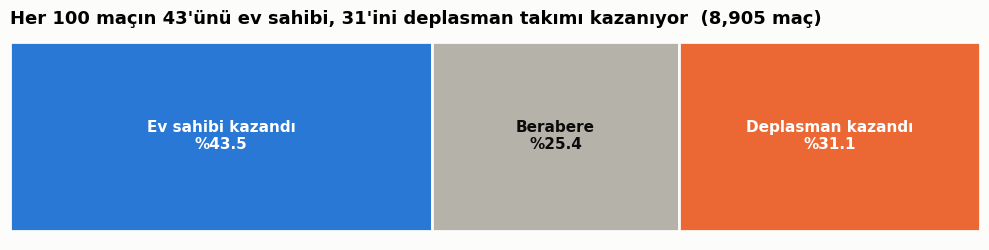

In [6]:
oran = df["sonuc"].value_counts(normalize=True).reindex(["E", "B", "D"]) * 100

fig, ax = plt.subplots(figsize=(10, 2.6))
sol = 0
for kod, renk, ad in [("E", EV, "Ev sahibi kazandı"), ("B", BERABERE, "Berabere"), ("D", DEP, "Deplasman kazandı")]:
    ax.barh(0, oran[kod], left=sol, color=renk, height=0.55, edgecolor="#fcfcfb", linewidth=2)
    ax.text(sol + oran[kod] / 2, 0, f"{ad}\n%{oran[kod]:.1f}", ha="center", va="center",
            color="#0b0b0b" if kod == "B" else "white", fontsize=11, fontweight="bold")
    sol += oran[kod]
ax.set_xlim(0, 100)
ax.axis("off")
ax.set_title(f"Her 100 maçın 43'ünü ev sahibi, 31'ini deplasman takımı kazanıyor  ({len(df):,} maç)")
plt.tight_layout()
plt.show()

**Evet, avantaj var ve küçük değil.** Ev sahibi, deplasman takımından **1,4 kat** daha sık kazanıyor.

Peki bu fark şans eseri olabilir mi? Beraberlikleri çıkarıp sadece kazananı olan maçlara bakıyorum. Avantaj olmasaydı, kazananın ev sahibi olma olasılığı %50 olurdu. **Binom testi** ile bunu her lig için ayrı ayrı sınıyorum:

In [7]:
test_satirlari = []
for lig, g in [*df.groupby("league"), ("TÜM LİGLER", df)]:
    ev_g, dep_g = (g["sonuc"] == "E").sum(), (g["sonuc"] == "D").sum()
    p = stats.binomtest(ev_g, ev_g + dep_g, p=0.5, alternative="greater").pvalue
    test_satirlari.append({"Lig": lig, "Kazananı olan maç": ev_g + dep_g,
                           "Kazanan ev sahibi (%)": round(ev_g / (ev_g + dep_g) * 100, 1),
                           "p-değeri": f"{p:.1e}", "Anlamlı (α=0.05)": "✅" if p < 0.05 else "❌"})
pd.DataFrame(test_satirlari).set_index("Lig")

,Kazananı olan maç,Kazanan ev sahibi (%),p-değeri,Anlamlı (α=0.05)
Lig,,,,
Bundesliga,1148,58.7,2.0e-09,✅
La Liga,1403,61.9,1.6e-19,✅
Ligue 1,1265,57.6,3.2e-08,✅
Premier League,1446,58.0,5.7e-10,✅
Serie A,1383,55.5,2.7e-05,✅
TÜM LİGLER,6645,58.4,1.0e-42,✅


Tüm liglerde p-değeri 0,05'in çok altında. **Ev sahibi avantajı tesadüf değil.** Kazananı olan maçların yaklaşık %58'ini ev sahibi kazanıyor.

### Soru 2: Avantaj her ligde aynı mı?

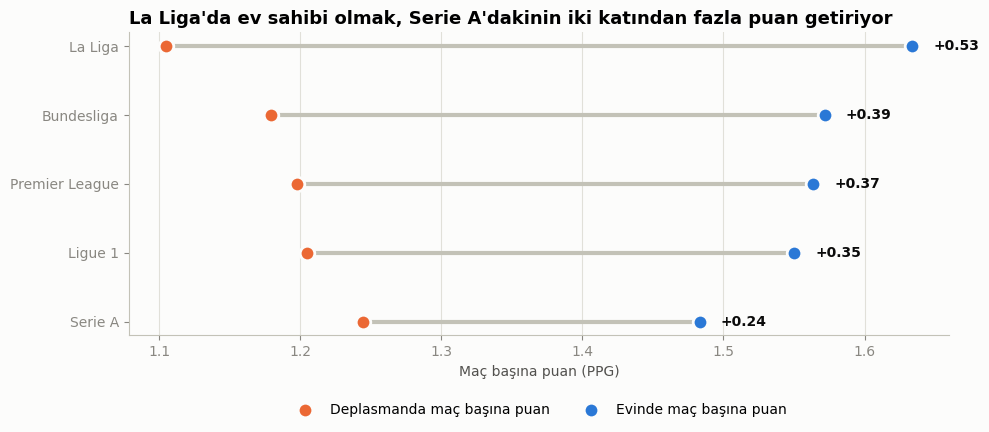

In [8]:
lig = df.groupby("league").agg(
    mac=("sonuc", "size"),
    ev_galibiyet=("sonuc", lambda s: (s == "E").mean() * 100),
    beraberlik=("sonuc", lambda s: (s == "B").mean() * 100),
    dep_galibiyet=("sonuc", lambda s: (s == "D").mean() * 100),
    ev_ppg=("ev_puan", "mean"), dep_ppg=("dep_puan", "mean"),
    ev_gol=("score.home", "mean"), dep_gol=("score.away", "mean"),
)
lig["avantaj_endeksi"] = lig["ev_ppg"] - lig["dep_ppg"]
lig["gol_farki"] = lig["ev_gol"] - lig["dep_gol"]
lig = lig.sort_values("avantaj_endeksi")

fig, ax = plt.subplots()
y = np.arange(len(lig))
ax.hlines(y, lig["dep_ppg"], lig["ev_ppg"], color="#c3c2b7", linewidth=3, zorder=1)
ax.scatter(lig["dep_ppg"], y, s=110, color=DEP, label="Deplasmanda maç başına puan", zorder=2, edgecolor="#fcfcfb", linewidth=2)
ax.scatter(lig["ev_ppg"], y, s=110, color=EV, label="Evinde maç başına puan", zorder=2, edgecolor="#fcfcfb", linewidth=2)
for i, (ad, s) in enumerate(lig.iterrows()):
    ax.text(s["ev_ppg"] + 0.015, i, f"+{s['avantaj_endeksi']:.2f}", va="center", fontweight="bold", color="#0b0b0b")
ax.set_yticks(y, lig.index)
ax.set_xlabel("Maç başına puan (PPG)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.set_title("La Liga'da ev sahibi olmak, Serie A'dakinin iki katından fazla puan getiriyor")
plt.tight_layout()
plt.show()

In [9]:
lig[["mac", "ev_galibiyet", "beraberlik", "dep_galibiyet", "avantaj_endeksi", "gol_farki"]] \
    .sort_values("avantaj_endeksi", ascending=False).round(2)

,mac,ev_galibiyet,beraberlik,dep_galibiyet,avantaj_endeksi,gol_farki
league,,,,,,
La Liga,1900,45.74,26.16,28.11,0.53,0.36
Bundesliga,1529,44.08,24.92,31.00,0.39,0.36
Premier League,1900,44.16,23.89,31.95,0.37,0.27
Ligue 1,1676,43.50,24.52,31.98,0.35,0.26
Serie A,1900,40.37,27.21,32.42,0.24,0.18


Avantaj her ligde var, ama büyüklüğü belirgin şekilde farklı:
- **La Liga** (+0,53) açık ara önde. Deplasman takımları burada maçların sadece %28'ini kazanabiliyor.
- **Serie A** (+0,24) en zayıf. İtalya'da beraberlik oranı da en yüksek (%27).
- Diğer üç lig (+0,34 ile +0,39 arası) birbirine çok yakın.

👉 **Tahmin modeli için çıkarım:** Tüm liglere tek bir ev sahibi katsayısı uygulamak, La Liga'da avantajı **olduğundan düşük**, Serie A'da ise **olduğundan yüksek** tahmin etmek demek.

### Soru 3: Avantaj zaman içinde sabit mi?

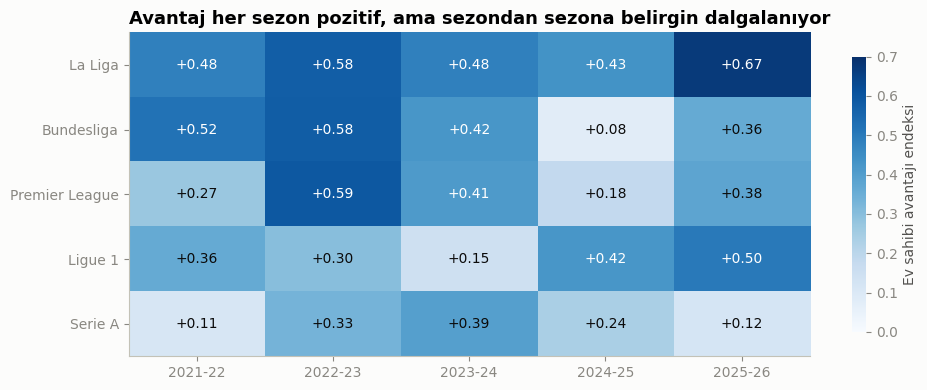

In [10]:
sezon = (df.assign(endeks=df["ev_puan"] - df["dep_puan"])
           .pivot_table(index="league", columns="season", values="endeks", aggfunc="mean")
           .loc[lig.index[::-1]])

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(sezon.values, cmap="Blues", vmin=0, vmax=0.7, aspect="auto")
ax.set_xticks(range(sezon.shape[1]), sezon.columns)
ax.set_yticks(range(sezon.shape[0]), sezon.index)
ax.grid(False)
for i in range(sezon.shape[0]):
    for j in range(sezon.shape[1]):
        v = sezon.iloc[i, j]
        ax.text(j, i, f"+{v:.2f}", ha="center", va="center", color="white" if v > 0.4 else "#0b0b0b")
cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Ev sahibi avantajı endeksi")
cbar.outline.set_visible(False)
ax.set_title("Avantaj her sezon pozitif, ama sezondan sezona belirgin dalgalanıyor")
plt.tight_layout()
plt.show()

- 25 lig-sezon kombinasyonunun **hepsinde** endeks sıfırın üzerinde.
- Ama dalgalanma büyük. Örneğin Bundesliga'da endeks 2022-23'te **+0,58** iken 2024-25'te **+0,08**'e düşmüş.
- La Liga dışındaki liglerde liderlik sezondan sezona el değiştiriyor.

👉 **Çıkarım:** Tek bir sezona bakarak "bu ligde ev sahibi avantajı kalmadı" demek yanıltıcı olur. Model katsayısı **birkaç sezonun ortalamasıyla** belirlenmeli.

### Soru 4: Hangi takımlar evinde bambaşka bir takım?

Her takımın iç saha ve dış saha PPG'sini ayrı ayrı hesaplıyorum. Küçük örneklem yanıltmasın diye en az **2 sezon** (38+ iç saha maçı) ligde kalan takımları dahil ediyorum.

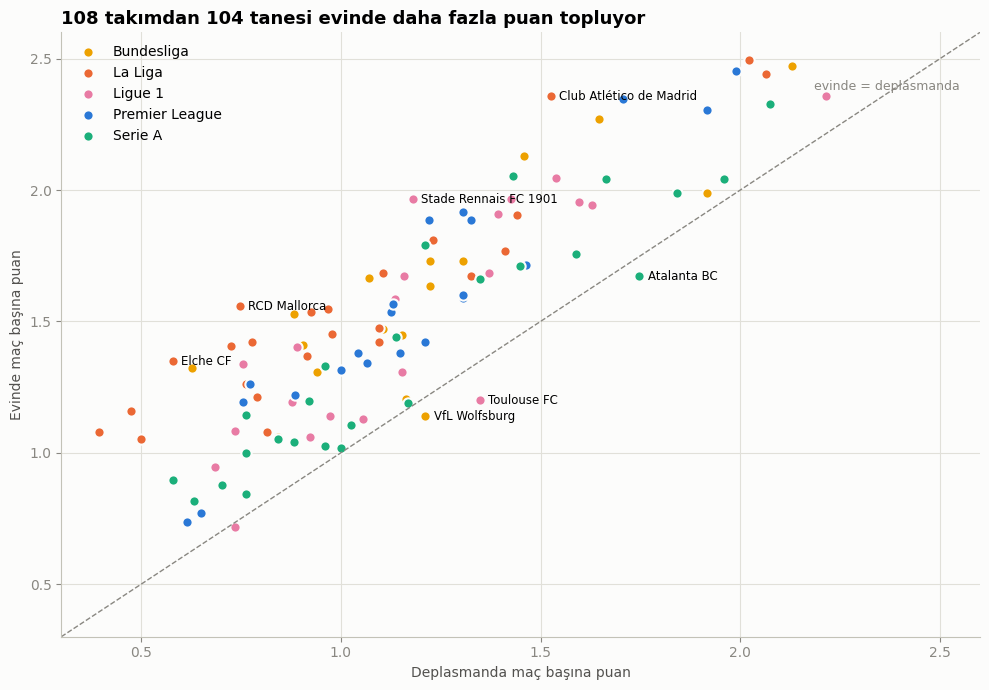

In [11]:
ic = df.groupby(["league", "homeTeam.name"]).agg(ic_mac=("ev_puan", "size"), ic_ppg=("ev_puan", "mean"))
dis = df.groupby(["league", "awayTeam.name"]).agg(dis_ppg=("dep_puan", "mean"))
takim = ic.join(dis.rename_axis(ic.index.names)).reset_index().rename(columns={"homeTeam.name": "takim"})
takim["fark"] = takim["ic_ppg"] - takim["dis_ppg"]
takim = takim[takim["ic_mac"] >= 38]

fig, ax = plt.subplots(figsize=(10, 7))
for ad, g in takim.groupby("league"):
    ax.scatter(g["dis_ppg"], g["ic_ppg"], s=55, color=LIG_RENK[ad], label=ad, edgecolor="#fcfcfb", linewidth=1.5)
ax.plot([0.3, 2.6], [0.3, 2.6], ls="--", color="#898781", lw=1)
ax.text(2.55, 2.42, "evinde = deplasmanda", color="#898781", ha="right", va="top", fontsize=9)
etiket = pd.concat([takim.nlargest(4, "fark"), takim.nsmallest(3, "fark")])
for _, s in etiket.iterrows():
    ax.annotate(s["takim"], (s["dis_ppg"], s["ic_ppg"]), xytext=(6, -3), textcoords="offset points", fontsize=8.5)
ax.set_xlim(0.3, 2.6)
ax.set_ylim(0.3, 2.6)
ax.set_xlabel("Deplasmanda maç başına puan")
ax.set_ylabel("Evinde maç başına puan")
ax.legend(loc="upper left")
ax.set_title(f"{len(takim)} takımdan {(takim['fark'] > 0).sum()} tanesi evinde daha fazla puan topluyor")
plt.tight_layout()
plt.show()

In [12]:
pd.concat({
    "🏠 Evinde en çok fark yaratanlar": takim.nlargest(5, "fark"),
    "✈️ Deplasmanda daha iyi olanlar": takim.nsmallest(3, "fark"),
})[["takim", "league", "ic_mac", "ic_ppg", "dis_ppg", "fark"]].round(2)

takim      league  \
🏠 Evinde en çok fark yaratanlar 28   Club Atlético de Madrid     La Liga   
                                39              RCD Mallorca     La Liga   
                                73     Stade Rennais FC 1901     Ligue 1   
                                31                  Elche CF     La Liga   
                                23           VfL Bochum 1848  Bundesliga   
✈️ Deplasmanda daha iyi olanlar 75               Toulouse FC     Ligue 1   
                                108              Atalanta BC     Serie A   
                                24             VfL Wolfsburg  Bundesliga   

                                     ic_mac  ic_ppg  dis_ppg  fark  
🏠 Evinde en çok fark yaratanlar 28       95    2.36     1.53  0.83  
                                39       95    1.56     0.75  0.81  
                                73       89    1.97     1.18  0.79  
                                31       57    1.35     0.58  0.77  
                                23       68    1.32     0.63  0.70  
✈️ Deplasmanda daha iyi olanlar 75       70    1.20     1.35 -0.15  
                                108      95    1.67     1.75 -0.07  
                                24       85    1.14     1.21 -0.07

- Takımların **ezici çoğunluğu** çizginin üstünde, yani evinde daha fazla puan topluyor.
- **Atlético Madrid** evinde maç başına 2,36 puanla bir şampiyonluk adayı gibi oynuyor. Deplasmanda ise 1,53 puanla orta-üst sıra takımı seviyesine iniyor.
- **Mallorca** ve **Elche** gibi küçük takımlar için iç saha, ligde kalmanın anahtarı. Bu takımlar puanlarının çok büyük kısmını evinde topluyor.
- **Toulouse, Atalanta ve Wolfsburg** ise kuralı bozan istisnalar.

👉 **İçerik ekibi için:** "Kalesi evi olan takımlar" ve "deplasman canavarları" gibi seriler bu veriyle doğrudan desteklenebilir.

### Soru 5: Avantaj sahaya nasıl yansıyor?

In [13]:
yari = pd.DataFrame({
    "Ev sahibi golü": [df["score.halfTime.home"].mean(), (df["score.home"] - df["score.halfTime.home"]).mean(), df["score.home"].mean()],
    "Deplasman golü": [df["score.halfTime.away"].mean(), (df["score.away"] - df["score.halfTime.away"]).mean(), df["score.away"].mean()],
}, index=["1. yarı", "2. yarı", "Maç sonu"])
yari["Fark"] = yari["Ev sahibi golü"] - yari["Deplasman golü"]
yari.round(2)

,Ev sahibi golü,Deplasman golü,Fark
1. yarı,0.69,0.56,0.13
2. yarı,0.85,0.70,0.15
Maç sonu,1.55,1.26,0.28


In [14]:
ev_onde = df[df["score.halfTime.home"] > df["score.halfTime.away"]]
dep_onde = df[df["score.halfTime.home"] < df["score.halfTime.away"]]
print(f"İlk yarıyı önde kapatan ev sahibi maçı kazanıyor   : %{(ev_onde['sonuc'] == 'E').mean() * 100:.1f}")
print(f"İlk yarıyı önde kapatan deplasman maçı kazanıyor  : %{(dep_onde['sonuc'] == 'D').mean() * 100:.1f}")

İlk yarıyı önde kapatan ev sahibi maçı kazanıyor   : %77.5
İlk yarıyı önde kapatan deplasman maçı kazanıyor  : %67.3


- Ev sahibi maç başına **~0,28 gol** fazla atıyor ve bu fark **iki yarıda da** görülüyor.
- Daha ilginci, öne geçen ev sahibi skoru daha iyi koruyor. İlk yarıyı önde kapatan ev sahibi maçların **%77,5**'ini kazanıyor; aynı durumdaki deplasman takımı ise **%67,3**'ünü.

Ev sahibi avantajı sadece daha çok gol atmak değil; **öndeyken maçı kaybetmemek** de demek.

## 5. Paylaş

### 📌 Temel bulgular

| # | Bulgu | Kanıt |
|---|---|---|
| 1 | Ev sahibi avantajı **gerçek ve istatistiksel olarak anlamlı** | Kazananı olan maçların %58'i ev sahibinin, p < 0,001 (5 ligin hepsinde) |
| 2 | Avantajın değeri **maç başına +0,37 puan** | Bir sezonda takım başına ~7 puan |
| 3 | **Ligler arasında büyük fark** var | La Liga +0,53, Serie A +0,24 |
| 4 | Avantaj **sezondan sezona dalgalanıyor** | Bundesliga: 2022-23'te +0,58, 2024-25'te +0,08 |
| 5 | Avantajın **takıma özel** bir boyutu var | Atlético evinde +0,83 PPG fazla; Toulouse deplasmanda daha iyi |
| 6 | Ev sahibi **öndeyken skoru daha iyi koruyor** | İlk yarıda önde: ev sahibi %77,5, deplasman %67,3 kazanıyor |

## 6. Harekete Geç

### 🎯 Müşteriye öneriler
1. **Lige özel ev sahibi katsayısı kullanın.** Tek bir değer yerine her lig için ayrı bir katsayı belirleyin: La Liga'da en yüksek, Serie A'da en düşük.
2. **Katsayıyı her sezon güncelleyin, ama son 3-5 sezonun ortalamasıyla.** Tek sezonluk veri çok oynak.
3. **Takım bazlı bir düzeltme ekleyin.** Atlético, Mallorca gibi iç-dış saha farkı ligin çok üstünde olan takımlar için ek ağırlık kullanın.
4. **İçerik fırsatı:** "Evinde yenilmez" ve "deplasman uzmanı" takım hikâyeleri, maç önü içeriklerde veriyle desteklenebilir.

### 🔭 Daha ileri keşif için eklenebilecek veriler
- **2019-21 COVID sezonları:** Seyircisiz oynanan maçlar, taraftar etkisini ölçmek için doğal bir deney.
- **Stadyum doluluk oranı ve seyirci sayısı:** Avantajın ne kadarının taraftardan geldiğini anlamak için.
- **Seyahat mesafesi:** Uzun deplasmanların etkisini ölçmek için.
- **Takım gücü (ör. Elo puanı) ve xG verisi:** Güçlü-zayıf takım etkisini kontrol eden bir regresyon modeli kurmak için.
- **Hakem kararları (kart ve penaltı):** Hakem yanlılığı hipotezini test etmek için.

### ⚠️ Kısıtlar
- Bu analiz avantajın **varlığını ve büyüklüğünü** gösteriyor, **nedenini** değil.
- 2021-23 ve 2023-26 sezonları iki farklı kaynaktan geliyor. Doğrulandılar, ama küçük tanım farkları olabilir.

### 💾 Özet dosyasını dışa aktarma
Lig bazlı özet tabloyu, model ekibinin doğrudan kullanabilmesi için kaydediyorum:

In [15]:
ozet = lig[["mac", "ev_galibiyet", "beraberlik", "dep_galibiyet", "ev_ppg", "dep_ppg", "avantaj_endeksi", "gol_farki"]] \
    .sort_values("avantaj_endeksi", ascending=False).round(3)
ozet.to_csv("lig_ozet_ev_sahibi_avantaji.csv")
ozet

,mac,ev_galibiyet,beraberlik,dep_galibiyet,ev_ppg,dep_ppg,avantaj_endeksi,gol_farki
league,,,,,,,,
La Liga,1900,45.74,26.16,28.11,1.63,1.10,0.53,0.36
Bundesliga,1529,44.08,24.92,31.00,1.57,1.18,0.39,0.36
Premier League,1900,44.16,23.89,31.95,1.56,1.20,0.37,0.27
Ligue 1,1676,43.50,24.52,31.98,1.55,1.21,0.34,0.26
Serie A,1900,40.37,27.21,32.42,1.48,1.25,0.24,0.18


---
*Okuduğunuz için teşekkürler! Notebook'u faydalı bulduysanız upvote vermeyi, sorularınızı ve önerilerinizi yorumlarda paylaşmayı unutmayın.* ⚽